# Лабораторная работа №1. Детектирование объектов с YOLOv8

6233 Саленая Юлия


## 1. Краткая теория и выбор модели

**Классификация** определяет класс изображения. **Детекция** находит отдельные объекты и выдаёт класс и прямоугольную рамку каждого объекта. **Сегментация** выделяет объекты или категории на уровне пикселей.

YOLOv8 — **one-stage** детектор: за один проход сети предсказывает рамки и классы без отдельного этапа предложения регионов. Backbone извлекает признаки, neck объединяет признаки разных масштабов, head предсказывает объекты. В YOLOv8 применяется anchor-free head с отдельными ветвями классификации и регрессии рамок.

SSD также относится к one-stage детекторам и использует признаки разных масштабов. Faster R-CNN — **two-stage** детектор: сначала RPN предлагает регионы, затем сеть уточняет их классы и координаты.

Перекрытие предсказанной рамки $B_p$ и истинной $B_g$:

$$IoU = \frac{|B_p \cap B_g|}{|B_p \cup B_g|}.$$

Предсказание считается верным при совпадении класса и достаточном IoU; один объект нельзя засчитать несколько раз. **Precision** — доля верных обнаружений среди предсказаний, **Recall** — доля обнаруженных объектов среди всех истинных объектов. **AP** обобщает precision–recall кривую для одного класса; **mAP** усредняет AP по классам.

- **mAP@0.50:** оценка при IoU = 0.50.
- **mAP@0.75:** более строгая оценка координат рамок.
- **mAP@0.50:0.95:** среднее по 10 порогам IoU от 0.50 до 0.95 с шагом 0.05.


In [ ]:
%pip -q install "ultralytics>=8.3,<9" "torchmetrics[detection]>=1.6,<2" tabulate

In [ ]:
from pathlib import Path
import random
import shutil
import xml.etree.ElementTree as ET
import importlib.metadata as metadata
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image, ImageDraw
from IPython.display import display
from ultralytics import YOLO
from ultralytics.utils.downloads import download
from ultralytics.utils import ASSETS_URL
from torchmetrics.detection.mean_ap import MeanAveragePrecision

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
EPOCHS = 20
IMGSZ = 640
BATCH = 8
N_TRAIN, N_VAL, N_TEST = 800, 200, 200
CLASSES = ['person', 'bicycle', 'car', 'cat', 'dog']
IOU_THRESHOLDS = [round(0.50 + 0.05 * i, 2) for i in range(10)]

BASE = Path('/content/lab1_yolov8')
DATA = BASE / 'voc5'
RESULTS = BASE / 'results'
RESULTS.mkdir(parents=True, exist_ok=True)

versions = {p: metadata.version(p) for p in
            ['ultralytics', 'torch', 'torchvision', 'torchmetrics', 'pycocotools']}
(RESULTS / 'versions.json').write_text(
    json.dumps(versions, indent=2), encoding='utf-8')


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Устройство: CPU
Версии: {'ultralytics': '8.4.209', 'torch': '2.14.1+cpu', 'torchvision': '0.29.1+cpu', 'torchmetrics': '1.9.0', 'pycocotools': '2.0.11'}
Для обучения рекомендуется включить GPU: на CPU выполнение будет медленным.


140

In [ ]:
RAW = BASE / 'raw'
VOC = RAW / 'VOCdevkit' / 'VOC2007'
if not (VOC / 'Annotations').exists():
    download(
        url=f'{ASSETS_URL}/VOCtrainval_06-Nov-2007.zip',
        dir=RAW, unzip=True, delete=False,
    )
assert (VOC / 'JPEGImages').exists(), 'Не удалось распаковать VOC2007.'

def read_annotation(xml_path):
    """Читаем XML VOC; координаты xyxy переводим в систему от нуля."""
    root = ET.parse(xml_path).getroot()
    w = int(root.findtext('size/width'))
    h = int(root.findtext('size/height'))
    objects = []
    for obj in root.findall('object'):
        name = obj.findtext('name')
        if name not in CLASSES:
            continue
        box = obj.find('bndbox')
        x1 = max(0, float(box.findtext('xmin')) - 1)
        y1 = max(0, float(box.findtext('ymin')) - 1)
        x2 = min(w, float(box.findtext('xmax')))
        y2 = min(h, float(box.findtext('ymax')))
        if x2 > x1 and y2 > y1:
            objects.append((CLASSES.index(name), x1, y1, x2, y2))
    return w, h, objects

annotations = {}
for xml_path in sorted((VOC / 'Annotations').glob('*.xml')):
    w, h, objects = read_annotation(xml_path)
    if objects:
        annotations[xml_path.stem] = (w, h, objects)

ids = list(annotations)
random.Random(SEED).shuffle(ids)
assert len(ids) >= N_TRAIN + N_VAL + N_TEST
splits = {
    'train': ids[:N_TRAIN],
    'val': ids[N_TRAIN:N_TRAIN + N_VAL],
    'test': ids[N_TRAIN + N_VAL:N_TRAIN + N_VAL + N_TEST],
}
assert not (set(splits['train']) & set(splits['val']))
assert not (set(splits['train']) & set(splits['test']))
assert not (set(splits['val']) & set(splits['test']))
print({name: len(items) for name, items in splits.items()})


Unzipping /content/lab1_yolov8/raw/VOCtrainval_06-Nov-2007.zip to /content/lab1_yolov8/raw/VOCdevkit...: 100% ━━━━━━━━━━━━ 10945/10945 3.5Kfiles/s 3.1s
{'train': 800, 'val': 200, 'test': 200}


Формат YOLO: для каждой картинки создаём текстовый файл с тем же именем. Одна строка — один объект: `class_id x_center y_center width height`. Координаты и размеры нормированы на ширину и высоту изображения. Наши ID классов: от 0 до 4.


In [ ]:
counts = {}
for split, image_ids in splits.items():
    image_dir = DATA / 'images' / split
    label_dir = DATA / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    # Убираем старые файлы только из созданной нами подвыборки при повторном запуске.
    for folder in (image_dir, label_dir):
        for old_file in folder.iterdir():
            if old_file.suffix.lower() in {'.jpg', '.txt', '.cache'}:
                old_file.unlink()
    count = np.zeros(len(CLASSES), dtype=int)
    for image_id in image_ids:
        w, h, objects = annotations[image_id]
        shutil.copy2(VOC / 'JPEGImages' / f'{image_id}.jpg', image_dir)
        lines = []
        for cls, x1, y1, x2, y2 in objects:
            values = [(x1 + x2) / (2*w), (y1 + y2) / (2*h),
                      (x2 - x1) / w, (y2 - y1) / h]
            assert all(0 <= value <= 1 for value in values)
            lines.append(str(cls) + ' ' + ' '.join(f'{v:.8f}' for v in values))
            count[cls] += 1
        (label_dir / f'{image_id}.txt').write_text('\n'.join(lines), encoding='utf-8')
    assert (count > 0).all(), f'В {split} отсутствует один из классов.'
    counts[split] = count

config = {'path': str(DATA), 'train': 'images/train',
          'val': 'images/val', 'test': 'images/test', 'names': CLASSES}
DATA_YAML = DATA / 'data.yaml'
DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False), encoding='utf-8')

distribution = pd.DataFrame(counts, index=CLASSES)
distribution.index.name = 'class'
display(distribution)
distribution.to_csv(RESULTS / 'class_distribution.csv')
(RESULTS / 'split_ids.json').write_text(
    json.dumps(splits, indent=2), encoding='utf-8')


,train,val,test
class,,,
person,1295,284,336
bicycle,120,23,9
car,373,94,89
cat,107,28,23
dog,128,21,35


16850

## 4. Предобученная модель: предсказания до обучения

В COCO модель знает 80 классов. Находим ID нужных классов **по названиям**, поскольку их номера отличаются от наших 0–4. Для картинок используем `conf=0.25`, чтобы рамки было удобно рассматривать. Ниже показываются изображения из validation; итоговые test-изображения сравним после обучения.


Соответствие ID COCO → наши ID: {0: 0, 1: 1, 2: 2, 15: 3, 16: 4}


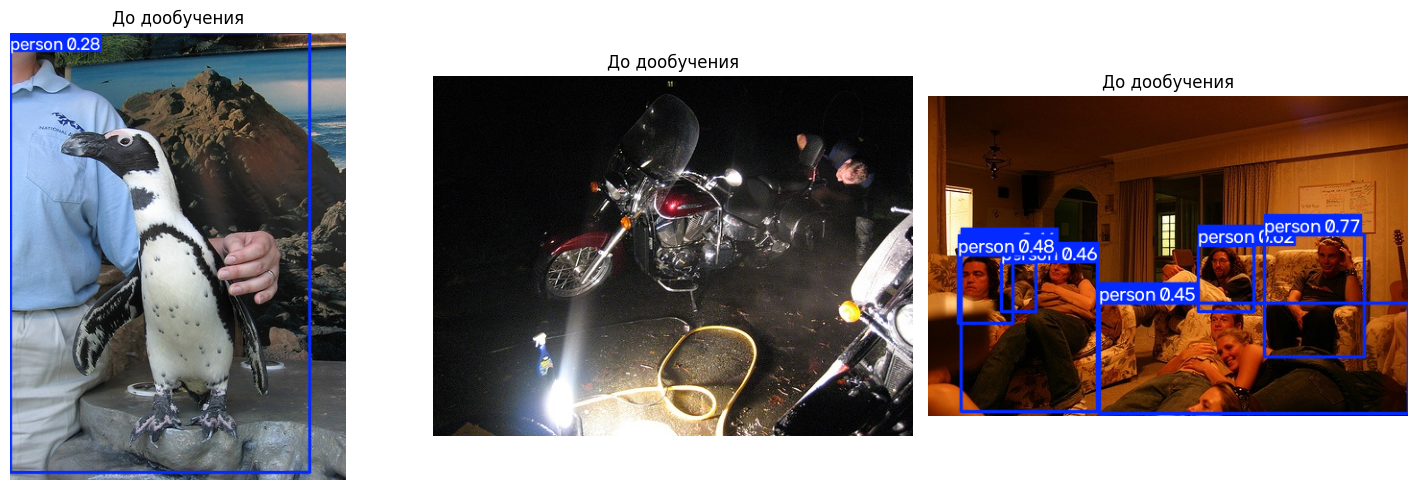

In [ ]:
before = YOLO('yolov8n.pt')
coco_to_custom = {idx: CLASSES.index(name)
                  for idx, name in before.names.items() if name in CLASSES}
COCO_IDS = list(coco_to_custom)
assert len(COCO_IDS) == len(CLASSES)
print('Соответствие ID COCO → наши ID:', coco_to_custom)

preview_paths = sorted((DATA / 'images' / 'val').glob('*.jpg'))[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, path in zip(axes, preview_paths):
    result = before.predict(str(path), classes=COCO_IDS, conf=0.25,
                            imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    ax.imshow(result.plot()[..., ::-1])  # Ultralytics возвращает BGR.
    ax.set_title('До дообучения')
    ax.axis('off')
plt.tight_layout()
plt.savefig(RESULTS / 'pretrained_examples.png', dpi=150)
plt.show()


## 5. Fine-tuning

Загружаем **отдельный экземпляр** предобученной модели, чтобы сохранить исходную для сравнения. Обучаются все слои; библиотека адаптирует выходную голову к пяти классам и переносит совместимые веса. `best.pt` выбирается по validation, а не по test.

20 эпох — небольшой учебный запуск. Рост качества не гарантирован: исходная модель уже знает эти категории, а подвыборка мала. Если нужно исследовать влияние длительности обучения, меняйте число эпох по результатам validation, сохраняя test для финальной оценки.


In [ ]:
finetune = YOLO('yolov8n.pt')
finetune.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    workers=2,
    optimizer='AdamW',
    lr0=0.001,
    patience=7,
    seed=SEED,
    deterministic=True,
    project=str(BASE / 'runs'),
    name='finetune',
    exist_ok=False,
    plots=True,
)
RUN = Path(finetune.trainer.save_dir)
after = YOLO(str(RUN / 'weights' / 'best.pt'))
print('Лучшая модель:', RUN / 'weights' / 'best.pt')


Ultralytics 8.4.209 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B13)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lab1_yolov8/voc5/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, opti

## 6. Графики обучения

Слева — ошибки локализации рамок и классификации; справа — качество на validation. Снижение train loss при ухудшении validation может указывать на переобучение. Значения Ultralytics на validation и итоговые TorchMetrics на test могут различаться из-за разных данных и деталей расчёта AP.


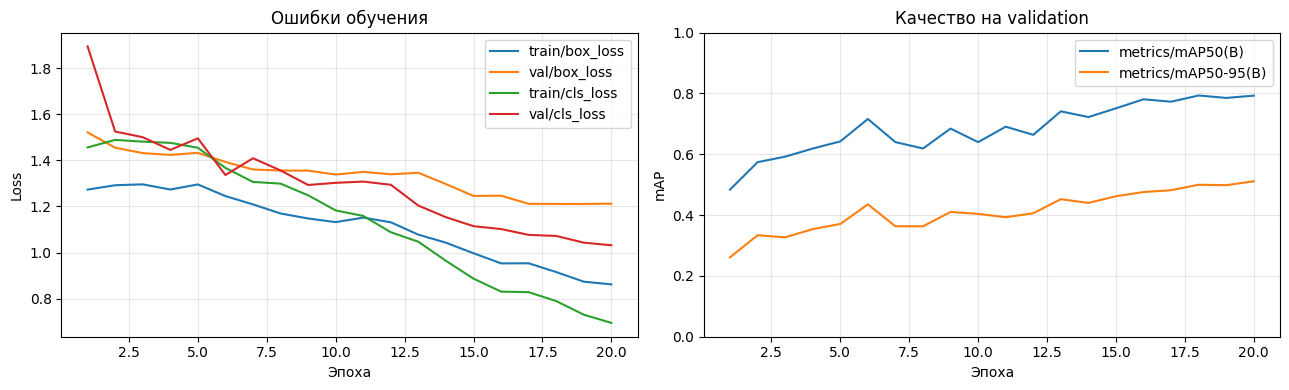

In [ ]:
history = pd.read_csv(RUN / 'results.csv')
history.columns = history.columns.str.strip()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col in ['train/box_loss', 'val/box_loss', 'train/cls_loss', 'val/cls_loss']:
    axes[0].plot(history['epoch'], history[col], label=col)
axes[0].set(xlabel='Эпоха', ylabel='Loss', title='Ошибки обучения')
for col in ['metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
    axes[1].plot(history['epoch'], history[col], label=col)
axes[1].set(xlabel='Эпоха', ylabel='mAP', title='Качество на validation', ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / 'learning_curves.png', dpi=150)
plt.show()


## 7. Оценка до и после на одном test

Ниже находится вспомогательная функция: она получает рамки, переводит классы в единую нумерацию и передаёт предсказания и истинные объекты в TorchMetrics. Для оценки ставим низкий порог уверенности `conf=0.001`, чтобы не обрезать precision–recall кривую. Для обеих моделей одинаковы размер изображения, NMS и лимит предсказаний.

**Не путайте два порога:** `iou=0.7` в `predict()` управляет удалением дублирующихся рамок (NMS). Пороги **оценки** 0.50–0.95 задаются отдельно в `MeanAveragePrecision`.


In [ ]:
test_paths = sorted((DATA / 'images' / 'test').glob('*.jpg'))

def evaluate(model, class_mapping):
    metric = MeanAveragePrecision(
        box_format='xyxy', iou_type='bbox',
        iou_thresholds=IOU_THRESHOLDS,
        class_metrics=True, extended_summary=True,
    )
    results = model.predict(
        source=[str(p) for p in test_paths], stream=True,
        classes=list(class_mapping), conf=0.001, iou=0.7,
        max_det=100, imgsz=IMGSZ, batch=BATCH,
        device=DEVICE, verbose=False,
    )
    for result in results:
        boxes = result.boxes
        labels = [class_mapping[int(c)] for c in boxes.cls.cpu().tolist()]
        prediction = {
            'boxes': boxes.xyxy.cpu().float(),
            'scores': boxes.conf.cpu().float(),
            'labels': torch.tensor(labels, dtype=torch.int64),
        }
        # Исходная XML-разметка уже прочитана в пикселях xyxy.
        objects = annotations[Path(result.path).stem][2]
        target = {
            'boxes': torch.tensor([obj[1:] for obj in objects], dtype=torch.float32).reshape(-1, 4),
            'labels': torch.tensor([obj[0] for obj in objects], dtype=torch.int64),
        }
        metric.update([prediction], [target])
    return metric.compute()

metrics_before = evaluate(before, coco_to_custom)
metrics_after = evaluate(after, {i: i for i in range(len(CLASSES))})


## 8. Таблицы и mAP при разных IoU

Расширенный результат TorchMetrics содержит precision с осями: **IoU × Recall × Class × Area × MaxDet**. Берём все размеры объектов (`Area=0`) и лимит 100 (`MaxDet=-1`), усредняем по recall и классам. Значение `-1` означает отсутствие данных для соответствующего элемента и исключается из среднего.


,Модель,mAP@0.50,mAP@0.75,mAP@0.50:0.95
0,До дообучения,0.8041,0.6715,0.6082
1,После дообучения,0.6378,0.4479,0.4261


,IoU,До,После
0,0.50,0.8041,0.6378
1,0.55,0.7948,0.6290
2,0.60,0.7806,0.6078
3,0.65,0.7669,0.5569
4,0.70,0.7165,0.5240
5,0.75,0.6715,0.4479
6,0.80,0.5916,0.3783
7,0.85,0.4684,0.2637
8,0.90,0.3362,0.1848
9,0.95,0.1508,0.0304


,Класс,AP@0.50:0.95 до,AP@0.50:0.95 после
0,person,0.6204,0.4980
1,bicycle,0.4707,0.2432
2,car,0.6811,0.6128
3,cat,0.6714,0.3545
4,dog,0.5972,0.4219


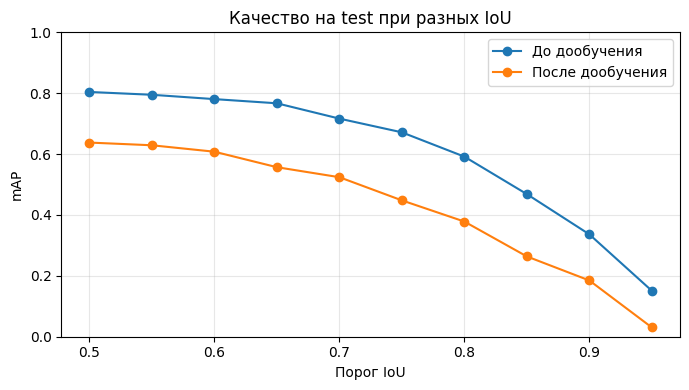

In [ ]:
def map_by_iou(metrics):
    precision = metrics['precision'][:, :, :, 0, -1]
    return [float(p[p >= 0].mean()) for p in precision]

summary = pd.DataFrame({
    'Модель': ['До дообучения', 'После дообучения'],
    'mAP@0.50': [float(m['map_50']) for m in [metrics_before, metrics_after]],
    'mAP@0.75': [float(m['map_75']) for m in [metrics_before, metrics_after]],
    'mAP@0.50:0.95': [float(m['map']) for m in [metrics_before, metrics_after]],
})
iou_table = pd.DataFrame({
    'IoU': IOU_THRESHOLDS,
    'До': map_by_iou(metrics_before),
    'После': map_by_iou(metrics_after),
})

def per_class_map(metrics):
    return dict(zip(metrics['classes'].tolist(), metrics['map_per_class'].flatten().tolist()))

class_before, class_after = per_class_map(metrics_before), per_class_map(metrics_after)
class_table = pd.DataFrame({
    'Класс': CLASSES,
    'AP@0.50:0.95 до': [class_before[i] for i in range(len(CLASSES))],
    'AP@0.50:0.95 после': [class_after[i] for i in range(len(CLASSES))],
})
display(summary.round(4))
display(iou_table.round(4))
display(class_table.round(4))

# Проверяем, что усреднение по IoU совпадает с общей метрикой.
assert np.isclose(iou_table['До'].mean(), float(metrics_before['map']), atol=1e-6)
assert np.isclose(iou_table['После'].mean(), float(metrics_after['map']), atol=1e-6)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(iou_table['IoU'], iou_table['До'], 'o-', label='До дообучения')
ax.plot(iou_table['IoU'], iou_table['После'], 'o-', label='После дообучения')
ax.set(xlabel='Порог IoU', ylabel='mAP', title='Качество на test при разных IoU', ylim=(0, 1))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / 'map_by_iou.png', dpi=150)
plt.show()

summary.to_csv(RESULTS / 'summary.csv', index=False)
iou_table.to_csv(RESULTS / 'map_by_iou.csv', index=False)
class_table.to_csv(RESULTS / 'per_class.csv', index=False)


## 9. Визуализация на одинаковых тестовых изображениях

Слева — истинные рамки, в центре — исходная YOLOv8, справа — дообученная. Для обеих моделей используем `conf=0.25` и одинаковые настройки. Показываем первые четыре файла в сортированном списке test, без отбора удачных примеров.

Сравните пропуски объектов, лишние рамки, классы и точность границ. Отсутствие рамки на картинке при `conf=0.25` не означает, что модель не выдала её с меньшей уверенностью при расчёте mAP.


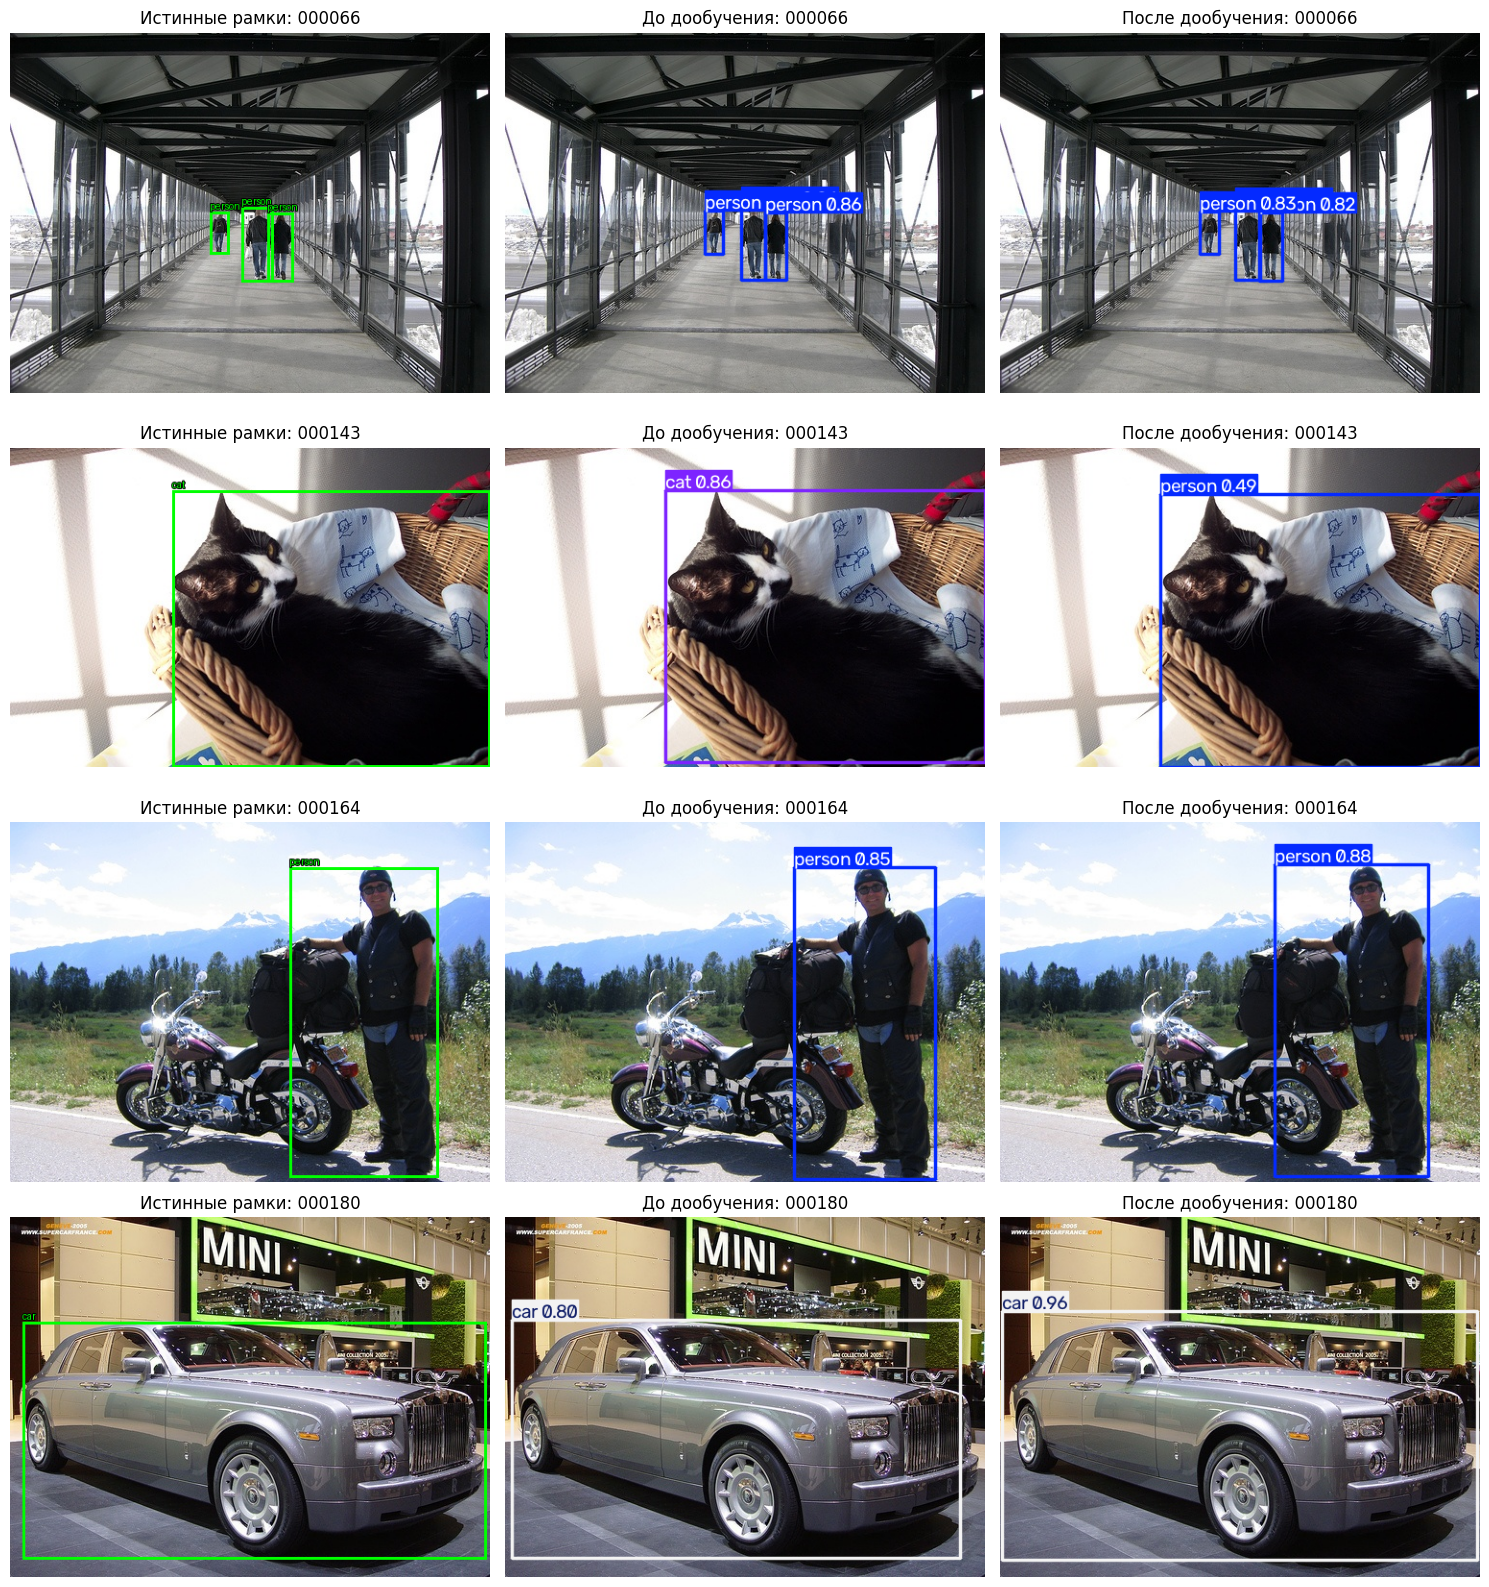

In [ ]:
examples = test_paths[:4]
fig, axes = plt.subplots(len(examples), 3, figsize=(15, 4 * len(examples)))
for row, path in enumerate(examples):
    image = Image.open(path).convert('RGB')
    draw = ImageDraw.Draw(image)
    for cls, x1, y1, x2, y2 in annotations[path.stem][2]:
        draw.rectangle((x1, y1, x2, y2), outline='lime', width=3)
        draw.text((x1, max(0, y1 - 12)), CLASSES[cls], fill='lime', stroke_width=1, stroke_fill='black')
    axes[row, 0].imshow(image)
    for col, model, selected in [(1, before, COCO_IDS), (2, after, list(range(5)))]:
        pred = model.predict(str(path), classes=selected, conf=0.25, iou=0.7,
                             max_det=100, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        axes[row, col].imshow(pred.plot()[..., ::-1])
    for col, title in enumerate(['Истинные рамки', 'До дообучения', 'После дообучения']):
        axes[row, col].set_title(f'{title}: {path.stem}')
        axes[row, col].axis('off')
plt.tight_layout()
plt.savefig(RESULTS / 'before_after.png', dpi=150)
plt.show()


## 10. Ответы на контрольные вопросы

**1. Чем one-stage детекторы отличаются от two-stage?**

One-stage детекторы, например YOLO и SSD, сразу предсказывают классы и рамки по признакам изображения. Two-stage детекторы, например Faster R-CNN, сначала предлагают регионы с возможными объектами, затем классифицируют и уточняют их. One-stage модели обычно удобны для быстрого обнаружения; two-stage модели выполняют дополнительную обработку регионов. Точность и скорость зависят от конкретной модели, данных и оборудования: two-stage не обязательно всегда точнее.

**2. Какие ошибки чаще всего допускает модель при детекции?**

- **Пропуск (FN):** объект есть, но модель его не обнаружила. Типичные причины — маленький размер, перекрытие, размытие, слабое освещение.
- **Ложное обнаружение (FP):** модель приняла фон за объект.
- **Ошибка класса:** рамка примерно верна, но класс перепутан, например кошка и собака.
- **Неточная локализация:** рамка смещена или включает слишком много фона. Такая ошибка особенно заметна при высоких порогах IoU.
- **Дублирование:** одному объекту соответствует несколько рамок; дополнительные рамки учитываются как FP.